# 42 · Block rescaling

**Question.** What does the descriptor's block rescaling buy, in its gap and in the field block's weight, and where does it stop?

In [1]:
from pathlib import Path

from pihm import plotting
from pihm.pipeline.results import Results

results = Results.at(Path("..").resolve())
CAMPAIGNS = ("p5_build", "p2_reproduction")
plotting.apply_style()
print(results.describe(CAMPAIGNS))

p5_build: 224 records, 224 ok
p2_reproduction: 327 records, 327 ok


In [2]:
from IPython.display import Markdown, display

from pihm.pipeline.results import reference_builds

builds = [r for r in results.rows("p5_build") if r["status"] == "ok"]
unscaled = [r for r in builds if r["label"] == "unscaled"]
problems = {r["problem"] for r in unscaled}
rescaled = [r for r in reference_builds(builds).values() if r["problem"] in problems]
standard = reference_builds(results.rows("p2_reproduction")).values()
series = {
    "descriptor": rescaled,
    "unscaled descriptor": unscaled,
    "standard": [r for r in standard if r["variant"] == "corrected" and r["problem"] in problems],
}


def axes(row):
    """Return how many axes a build's field has."""
    return len(str(row["qubits"]).split(";"))


def at(name, problem, n):
    """Return a series' row of a problem at n, if it has one."""
    return next((r for r in series[name] if r["problem"] == problem and r["n"] == n), None)


def span(values):
    """Return a range of values to two significant figures."""
    return f"{min(values):.2g} to {max(values):.2g}"


gains, weights, per_qubit = [], {"descriptor": [], "unscaled descriptor": []}, {1: [], 2: []}
for problem in sorted(problems):
    rows = sorted((r for r in rescaled if r["problem"] == problem), key=lambda r: r["n"])
    last, plain = rows[-1], at("unscaled descriptor", problem, rows[-1]["n"])
    gains.append(last["gap"] / plain["gap"])
    weights["descriptor"].append(last["field_weight"])
    weights["unscaled descriptor"].append(plain["field_weight"])
    trusted = [r for r in rows if r["trusted"]]
    if len(trusted) >= 2:
        steps = trusted[-1]["n"] - trusted[0]["n"]
        per_qubit[axes(last)].append((trusted[-1]["gap"] / trusted[0]["gap"]) ** (1 / steps))
top = sorted({r["n"] for r in rescaled if axes(r) == 1})[-1]
lines = [
    f"- At each problem's largest n, rescaling multiplies the gap by {span(gains)}, and the field "
    f"block's weight in the ground state is {span(weights['descriptor'])}, against "
    f"{span(weights['unscaled descriptor'])} unscaled.",
    f"- Over each problem's trusted resolutions, the rescaled gap changes by "
    f"×{span(per_qubit[1])} per qubit on one axis (to n = {top}), and by ×{span(per_qubit[2])} "
    "per qubit per axis on two.",
]
display(Markdown("\n".join(lines)))

- At each problem's largest n, rescaling multiplies the gap by 2.9 to 4e+10, and the field block's weight in the ground state is 0.18 to 1, against 5.4e-06 to 0.088 unscaled.
- Over each problem's trusted resolutions, the rescaled gap changes by ×0.99 to 2 per qubit on one axis (to n = 10), and by ×0.17 to 0.68 per qubit per axis on two.

The gap against n, rescaled and unscaled, with the standard form's beside them. The panels share
their axes; a flat line is a gap the resolution does not close.

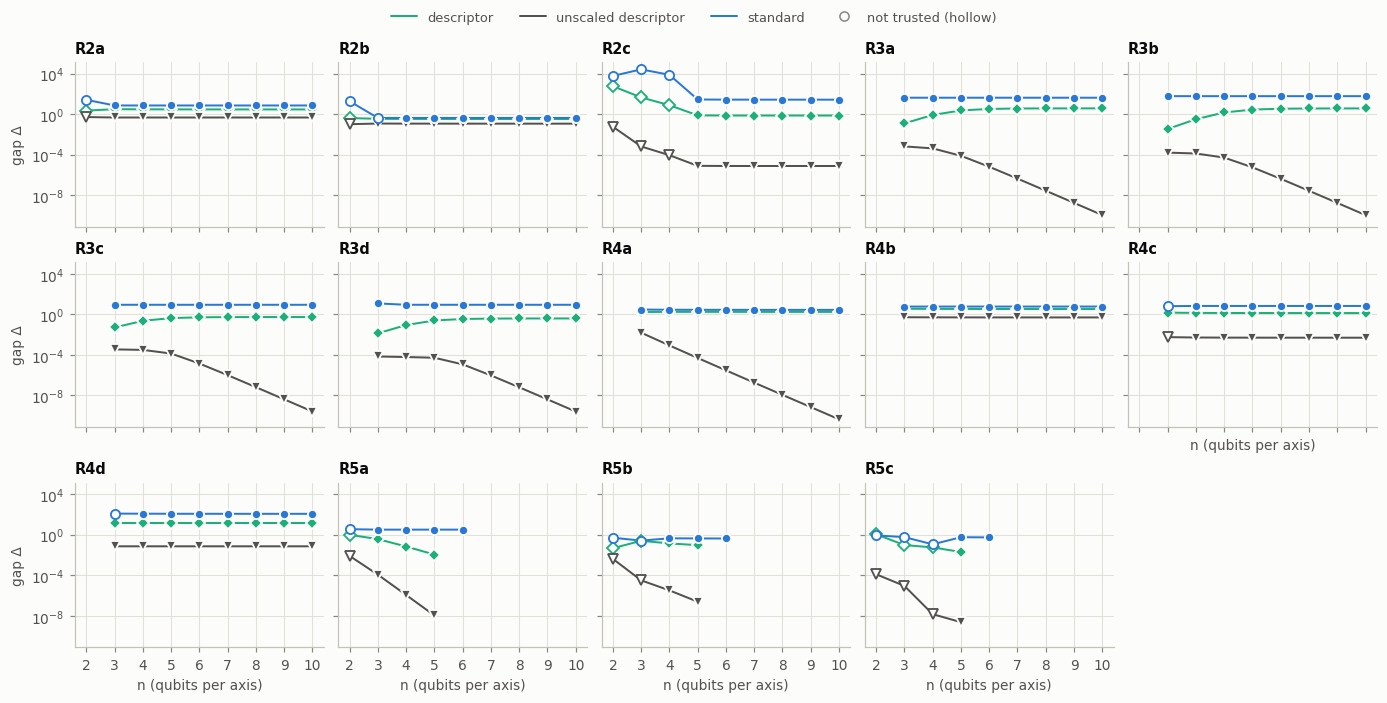

In [3]:
plotting.by_resolution(series, "gap", "gap Δ");

The field block's weight in the ground state: an initial state on the field block overlaps the
ground state at most by this much, so amplitude amplification's cost grows as it falls.

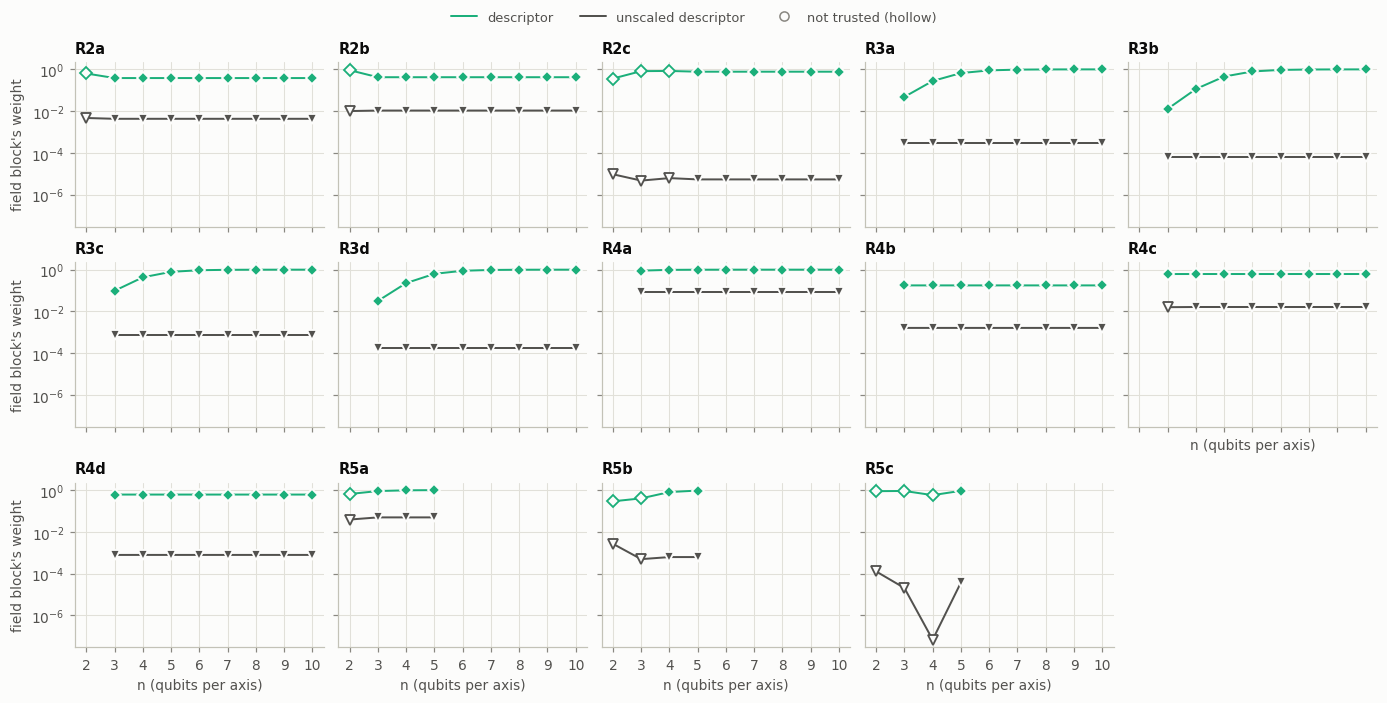

In [4]:
weighted = {name: rows for name, rows in series.items() if name != "standard"}
plotting.by_resolution(weighted, "field_weight", "field block's weight");

**What this does not show.** These are the classical builds; the cost they imply is notebook 40's
and 41's. R1, a first-order equation, is carried in mass form with no derivative block to
rescale. The paper-faithful R3c and R3d, whose leading coefficient has a double zero, are beyond any
block rescaling and the descriptor does not run them.